# Nudge Problem: Transformer

This notebook follows **Week 8** (attention, multi-head attention, positions, the Transformer block, encoders, the `<cls>` token) and reuses the **Transformers workshop** (`1_name_generator.ipynb`): `attention`, `SelfAttention` and `Block` are the workshop's code, unchanged, in `nudge/transformer.py`.

The task changes from the workshop's "predict the next letter" to **one yes/no per visit**: will this shopper come back and buy within 7 days on their own?

1. Read each visit as a sequence of click words, like the RNN in `03_rnn`.
2. Let every click look at every other click (self-attention), with a **padding mask** instead of the causal mask.
3. Use the output of the first position as the summary of the visit, like `<cls>`.
4. Train with the same loop, score **once** on the same test shoppers, and compare with logistic regression and the RNN.
5. Look inside: which clicks did the model look at?

**Owner:** TBD (Main model role)

## 0. One-time setup
The project's `.venv` already has everything. On a new computer:

In [1]:
# %pip install -r ../requirements.txt

## 1. Import the packages
- `nudge.transformer`: the workshop's `attention`, `SelfAttention`, `Block`, and our `VisitTransformer`
- `nudge.train`, `nudge.evaluate`: the same helpers as `02_baselines` and `03_rnn`

In [2]:
import sys, pathlib, inspect
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

from nudge.train import SEED, BLOCK_SIZE, VOCAB_SIZE, set_seed, visits_to_ids, make_loader, train_model, predict_proba, plot_history
from nudge.evaluate import pick_cutoff, quality, money, bootstrap
from nudge import transformer
from nudge.transformer import VisitTransformer

set_seed(SEED)
torch.set_num_threads(4)
device = torch.device("cpu")    # measured: about 2x faster than the Apple GPU for this small model, and repeatable

## 2. Load the visits
The same visits, split **by shopper**, as in every other notebook.

In [3]:
visits = pd.read_parquet("../data/raw/visits_10pct.parquet")
train_df = visits[visits["split"] == "train"].reset_index(drop=True)
val_df = visits[visits["split"] == "valid"].reset_index(drop=True)
test_df = visits[visits["split"] == "test"].reset_index(drop=True)
y = {"train": train_df["label"].to_numpy(), "val": val_df["label"].to_numpy(), "test": test_df["label"].to_numpy()}
X = {name: visits_to_ids(df["tokens"]) for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]}
print({name: x.shape for name, x in X.items()})

{'train': (933419, 64), 'val': (115544, 64), 'test': (117531, 64)}


## 3. Attention, from the workshop
Each click asks a question (query $q$), every click offers a label (key $k$) and content (value $v$). The answer is a weighted blend (Week 8 s17–s20):
$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d}}\right)V$$
Dividing by $\sqrt{d}$ keeps the scores on one scale; softmax makes the weights positive and sum to 1. This is the workshop's function, unchanged:

In [4]:
print(inspect.getsource(transformer.attention))

def attention(q, k, v, mask):
    # q, k, v: (..., positions, d).  mask: True where a position may be looked at.   (workshop c6)
    d = q.shape[-1]
    scores = q @ k.transpose(-2, -1) / math.sqrt(d)          # softmax(QK^T / sqrt(d)) V, Week 8 s20
    scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    output = torch.matmul(weights, v)
    return output, weights



## 4. What changes for Nudge
**Mask.** In the workshop, each letter may only look at letters **before** it (causal mask), because it must guess the next one (Week 8 s28). We score a **finished** visit, so every click may look at every other click, like an encoder (Week 8 s22). We only hide the padding (Week 8 s20: "padding is masked out").

**One answer per visit.** Our first word is always `new` or `returning`. With no causal mask it can look at every click, so its output after the blocks summarises the whole visit, like the `<cls>` token of Week 8 s31. One linear layer + sigmoid turns it into a probability (Week 3 s16).

**Order.** Self-attention alone does not know the order ("dog bites man", Week 8 s25), so, as in the workshop, a learned position embedding is added: $X + P$.

**Size.** The workshop's settings: $d = 32$, 2 heads, 2 blocks, dropout 0.2.

In [5]:
print(inspect.getsource(transformer.padding_mask))
print(inspect.getsource(VisitTransformer))
set_seed(SEED)
model = VisitTransformer(VOCAB_SIZE, BLOCK_SIZE, d=32, heads=2, blocks=2, dropout=0.2).to(device)
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

def padding_mask(ids):
    # True where a word may be looked at: every real word; <pad> (id 0) is hidden. Shape (visits, 1, 1, positions)
    return (ids != 0)[:, None, None, :]

class VisitTransformer(nn.Module):
    # Click words in, one chance to come back and buy out.

    def __init__(self, vocab_size, block_size, d=32, heads=2, blocks=2, dropout=0.2):
        super().__init__()
        self.settings = {"vocab_size": vocab_size, "block_size": block_size, "d": d, "heads": heads,
                         "blocks": blocks, "dropout": dropout}
        self.word_embedding = nn.Embedding(vocab_size, d)          # what the click is   (workshop: letter_embedding)
        self.position_embedding = nn.Embedding(block_size, d)      # where it stands
        self.blocks = nn.ModuleList([Block(d, heads, dropout) for _ in range(blocks)])
        self.to_logit = nn.Linear(d, 1)                             # workshop: to_scores = Linear(d, vocab_size)

    def forward(self, ids):
        longest 

## 5. Check the padding mask
A positive and a negative control: adding more padding must **not** change the answer; adding a real click **must**.

In [6]:
model.eval()
a = torch.tensor([[1, 5, 9, 12, 0, 0], [2, 7, 0, 0, 0, 0]])
b = torch.zeros(2, BLOCK_SIZE, dtype=torch.long); b[:, :6] = a
c = a.clone(); c[0, 4] = 30
with torch.no_grad():
    print("same answer with extra padding:", torch.allclose(model(a), model(b), atol=1e-6))
    print("answer changes when a real click is added:", not torch.allclose(model(c)[0], model(a)[0]))

same answer with extra padding: True
answer changes when a real click is added: True


## 6. Train
The same loop as every other model: forward pass, binary cross-entropy (Week 3 s18), backward pass, AdamW step (the workshop's optimizer), keep the epoch with the lowest validation loss.

/Users/kriksciunas/nudge-main/nudge/train.py:63: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  target_tensor = torch.as_tensor(targets, dtype=torch.float32)


Epoch  1/6 | train loss 0.2776 | val loss 0.2738 | val PR-AUC 0.176


Epoch  2/6 | train loss 0.2756 | val loss 0.2737 | val PR-AUC 0.177


Epoch  3/6 | train loss 0.2753 | val loss 0.2736 | val PR-AUC 0.178


Epoch  4/6 | train loss 0.2752 | val loss 0.2736 | val PR-AUC 0.178


Epoch  5/6 | train loss 0.2750 | val loss 0.2733 | val PR-AUC 0.179


Epoch  6/6 | train loss 0.2749 | val loss 0.2737 | val PR-AUC 0.177


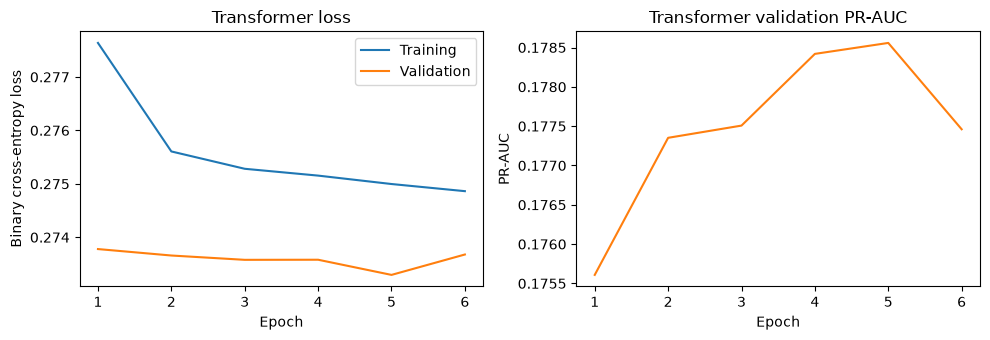

In [7]:
train_loader = make_loader(X["train"], y["train"], batch_size=512, shuffle=True)
val_loader = make_loader(X["val"], y["val"], batch_size=4096)
test_loader = make_loader(X["test"], y["test"], batch_size=4096)

set_seed(SEED)
model = VisitTransformer(VOCAB_SIZE, BLOCK_SIZE, d=32, heads=2, blocks=2, dropout=0.2).to(device)
history = train_model(model, train_loader, val_loader, nn.BCEWithLogitsLoss(), torch.optim.AdamW(model.parameters(), lr=0.001), epochs=6)
plot_history(history, "Transformer")

## 7. Test once, next to every other model
The baselines and the RNN were saved by `02_baselines` and `03_rnn` (`results/scores/`), so all models are compared on exactly the same test visits, each with the cut-off it chose on validation.

In [8]:
scores_test = {name: np.load(f"../results/scores/{file}_test.npy") for name, file in
               [("Industry rule", "industry_rule"), ("Logistic regression", "logistic_regression"), ("RNN", "rnn")]}
transformer_val = predict_proba(model, val_loader)
scores_test["Transformer"] = predict_proba(model, test_loader)
cutoffs = {"Industry rule": 0.5, "Transformer": pick_cutoff(y["val"], transformer_val),
           "Logistic regression": torch.load("../results/logistic_regression.pt")["cutoff"],
           "RNN": torch.load("../results/rnn.pt")["cutoff"]}

rows = []
for name, s in scores_test.items():
    q = quality(y["test"], s, cutoffs[name])
    ci = bootstrap(test_df.assign(_s=s), lambda d, c=cutoffs[name]: {k: quality(d["label"].to_numpy(), d["_s"].to_numpy(), c)[k] for k in ("auc", "pr_auc")}, n=200, seed=SEED)
    rows.append({"model": name, **{k: round(q[k], 3) for k in ("auc", "pr_auc", "precision", "recall", "f1")},
                 "auc_95%": f"{ci['auc'][0]:.3f}–{ci['auc'][1]:.3f}", "pr_auc_95%": f"{ci['pr_auc'][0]:.3f}–{ci['pr_auc'][1]:.3f}"})
quality_table = pd.DataFrame(rows).set_index("model")
quality_table

,auc,pr_auc,precision,recall,f1,auc_95%,pr_auc_95%
model,,,,,,,
Industry rule,0.558,0.124,0.209,0.184,0.196,0.551–0.564,0.118–0.130
Logistic regression,0.676,0.157,0.161,0.370,0.224,0.670–0.682,0.148–0.165
RNN,0.679,0.163,0.169,0.323,0.222,0.673–0.685,0.153–0.170
Transformer,0.682,0.168,0.166,0.359,0.227,0.676–0.688,0.159–0.176


## 8. Is the Transformer really better? A paired comparison
Two overlapping ranges do not settle it. The fair test resamples the **same** shoppers for both models and looks at the **difference** each time. If the 95% range of the difference stays above 0, the gain is not luck.

In [9]:
frame = test_df.assign(_tr=scores_test["Transformer"], _rnn=scores_test["RNN"], _lr=scores_test["Logistic regression"])
def differences(d):
    yy = d["label"].to_numpy()
    auc = {k: quality(yy, d[k].to_numpy(), 0.5)["auc"] for k in ("_tr", "_rnn", "_lr")}
    return {"Transformer − Logistic regression (AUC)": auc["_tr"] - auc["_lr"],
            "Transformer − RNN (AUC)": auc["_tr"] - auc["_rnn"],
            "RNN − Logistic regression (AUC)": auc["_rnn"] - auc["_lr"]}
point = differences(frame)
ranges = bootstrap(frame, differences, n=200, seed=SEED)
pd.DataFrame({"difference": {k: round(v, 4) for k, v in point.items()},
              "95% range": {k: f"{lo:+.4f} to {hi:+.4f}" for k, (lo, hi) in ranges.items()},
              "clearly better?": {k: "yes" if lo > 0 else "no" for k, (lo, hi) in ranges.items()}})

,difference,95% range,clearly better?
Transformer − Logistic regression (AUC),0.0062,+0.0042 to +0.0087,yes
Transformer − RNN (AUC),0.0034,+0.0018 to +0.0050,yes
RNN − Logistic regression (AUC),0.0028,+0.0009 to +0.0051,yes


## 9. Does order matter? By visit length, and by shuffling
Self-attention links any two clicks in one step (Week 8 s24), while an RNN passes everything through one $H_t$ and early clicks fade (Week 8 s14, Week 6 s31). If that matters, the Transformer should gain most on **long** visits. And shuffling the clicks should hurt it if it uses their order.

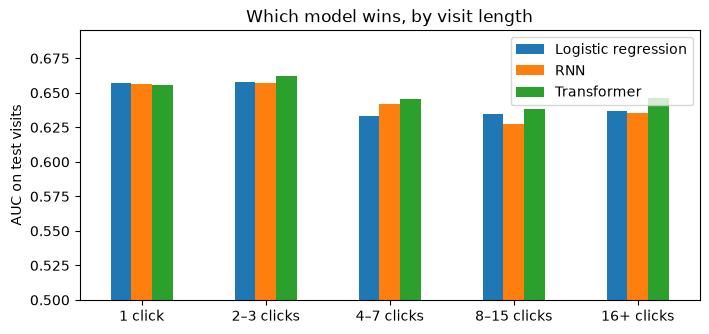

Transformer AUC, real order: 0.682 | shuffled clicks: 0.680


,Logistic regression,RNN,Transformer
1 click,0.657,0.657,0.656
2–3 clicks,0.658,0.657,0.662
4–7 clicks,0.633,0.642,0.646
8–15 clicks,0.634,0.628,0.638
16+ clicks,0.637,0.636,0.646


In [10]:
length = (X["test"] != 0).sum(axis=1)
groups = pd.cut(length, [0, 2, 4, 8, 16, 65], labels=["1 click", "2–3 clicks", "4–7 clicks", "8–15 clicks", "16+ clicks"])
by_length = pd.DataFrame({name: [quality(y["test"][groups == g], scores_test[name][groups == g], 0.5)["auc"] for g in groups.categories]
                          for name in ("Logistic regression", "RNN", "Transformer")}, index=groups.categories)
by_length.plot.bar(figsize=(8, 3.5), rot=0)
plt.ylabel("AUC on test visits"); plt.ylim(0.5, None); plt.title("Which model wins, by visit length"); plt.show()

rng = np.random.default_rng(SEED)
shuffled = X["test"].copy()
for row, n in enumerate(length):
    if n > 2:
        shuffled[row, 1:n] = rng.permutation(shuffled[row, 1:n])
auc_shuffled = quality(y["test"], predict_proba(model, make_loader(shuffled, y["test"], batch_size=4096)), 0.5)["auc"]
print(f"Transformer AUC, real order: {quality_table.loc['Transformer', 'auc']:.3f} | shuffled clicks: {auc_shuffled:.3f}")
by_length.round(3)

## 10. Money: who gets the 10% discount?
Same rule for every model: cart abandoners only; each model ranks them and discounts the 60% it thinks are **least** likely to come back on their own (the ranking uses no labels); at most one discount per shopper per 7 days.

In [11]:
test_cart = test_df["cart_value"].to_numpy() > 0
rule = money(test_df, np.ones(len(test_df), dtype=bool))
money_rows = [{"policy": "Industry rule (everyone)", "discounts": rule["discounts_sent"], "€ wasted": round(rule["wasted_eur"]), "left without a nudge": rule["left_without_nudge"]}]
for name in ("Logistic regression", "RNN", "Transformer"):
    cut = np.quantile(scores_test[name][test_cart], 0.6)
    give = scores_test[name] < cut
    m = money(test_df, give)
    ci = bootstrap(test_df.assign(_g=give), lambda d: money(d, d["_g"].to_numpy()), n=200, seed=SEED)
    money_rows.append({"policy": f"{name} (60%)", "discounts": m["discounts_sent"], "€ wasted": round(m["wasted_eur"]),
                       "€ wasted 95%": f"{ci['wasted_eur'][0]:,.0f}–{ci['wasted_eur'][1]:,.0f}", "left without a nudge": m["left_without_nudge"]})
money_table = pd.DataFrame(money_rows)
money_table

,policy,discounts,€ wasted,left without a nudge,€ wasted 95%
0,Industry rule (everyone),6622,50327,1568,NaN
1,Logistic regression (60%),4632,30234,3128,"26,407–34,453"
2,RNN (60%),4672,28379,3052,"24,640–31,770"
3,Transformer (60%),4690,26766,3051,"23,718–30,382"


## 11. Look inside: what did the model look at?
The workshop's heatmap (c21), now for one real test visit. Row 1 is the summary position (`new`/`returning`): it shows **which clicks the model used** for its decision. Unlike the workshop's triangle, the whole square is filled, because there is no causal mask.

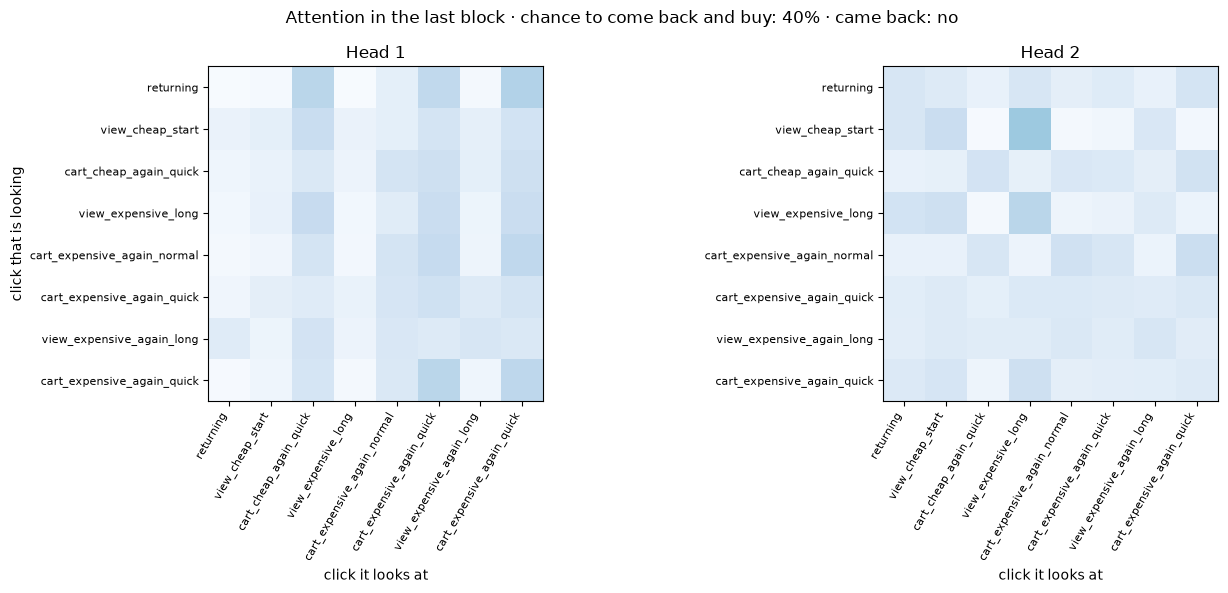

In [12]:
long_visits = np.where((length >= 7) & (length <= 10))[0]
pick = long_visits[np.argmax(scores_test["Transformer"][long_visits])]     # the 7–10 click visit the model is most sure about
ids = torch.as_tensor(X["test"][pick:pick + 1])
model.eval()
with torch.no_grad():
    chance = torch.sigmoid(model(ids)).item()
weights = model.blocks[-1].attention.weights[0]                          # (heads, positions, positions)
labels = list(test_df["tokens"][pick])
fig, axes = plt.subplots(1, weights.shape[0], figsize=(7 * weights.shape[0], 6), squeeze=False)
for head, ax in enumerate(axes[0]):
    ax.imshow(weights[head].tolist(), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("click it looks at"); ax.set_title(f"Head {head + 1}")
axes[0][0].set_ylabel("click that is looking")
fig.suptitle(f"Attention in the last block · chance to come back and buy: {chance:.0%} · came back: {'yes' if y['test'][pick] else 'no'}")
plt.tight_layout(); plt.show()

## 12. Save the model and results

In [13]:
out = pathlib.Path("../results")
quality_table.to_csv(out / "transformer_quality.csv")
by_length.round(3).to_csv(out / "transformer_by_length.csv")
money_table.to_csv(out / "transformer_money.csv", index=False)
np.save(out / "scores" / "transformer_test.npy", scores_test["Transformer"].astype(np.float32))
torch.save({"config": model.settings, "state_dict": model.state_dict(), "cutoff": cutoffs["Transformer"], "seed": SEED},
           out / "transformer.pt")
print("saved")

saved


## 13. Connect the code to the course
| Idea | Where it appears here | Course |
|---|---|---|
| Scaled dot-product attention $\text{softmax}(QK^\top/\sqrt{d})V$ | section 3, `attention` | Week 8 s17–s20, workshop c6 |
| Multi-head attention | `SelfAttention`, 2 heads | Week 8 s23, workshop c15 |
| Position embedding $X + P$ | `VisitTransformer.forward` | Week 8 s25, workshop c15 |
| Transformer block: attention, add & norm, MLP, add & norm | `Block` | Week 8 s26–s27, workshop c15 |
| Padding mask instead of causal mask | sections 4–5, `padding_mask` | Week 8 s20, s28 |
| Encoder for classification, `<cls>` summary | section 4, output of position 1 | Week 8 s22, s31–s32 |
| Attention heatmap | section 11 | workshop c21 |
| Is the complex model worth it? | sections 8–10 | Week 8 s6 |

## Reflection questions
1. Why does the workshop need a causal mask but Nudge does not? What would go wrong if we kept it?
2. Why is the first word (`new`/`returning`) a good place to read the summary from?
3. In the heatmap, which clicks does the summary row look at most? Does that match logistic regression's word weights?
4. If the paired comparison says the Transformer is not clearly better than the RNN, which model would you put into production, and why?